# Where does the Lomb-Scargle hit rate drop past 13.7 d?
Question from 2026-10-16: how many days beyond TARS can we go, at a granular level?
```
hit = |P_peak - P_true| < 0.1 x P_true          (same LS and same rule as the earlier summary)

(1) MEarth truth in 2-day bins                    --> section 1
(2) more truth stars: Emily Pass's samples        --> section 2  (suggestion from 2026-10-30)
(3) more truth stars: McQuillan+2013 Kepler M dwarfs --> section 3  (suggested by Alan Xia)
```

In [1]:
import sys
from pathlib import Path

import pandas as pd

pd.set_option("display.max_colwidth", None)

repo = Path.cwd().parent
sys.path.insert(0, str(repo / "src"))
import granular_mearth
import pass_samples

results = repo / "results"
%matplotlib inline

## 1. First try: real MEarth stars in 2-day bins
Number on top = star-sectors (left) or stars (right) in that bin. Error bars: Wilson 68%.

centre     = (p + z^2 / (2n)) / (1 + z^2 / n)

half_width = z * sqrt( p(1-p)/n + z^2/(4n^2) ) / (1 + z^2 / n)

error bar  = [centre - half_width, centre + half_width]

Dotted line = chance: the hit rate of a peak that ignores the star.
```
chance(bin) = fraction of pairs (truth period of a star in this bin, LS peak of any star at 8-30 d) that count as a hit
hit rate ~ chance  -->  the peak carries no information about the period
```

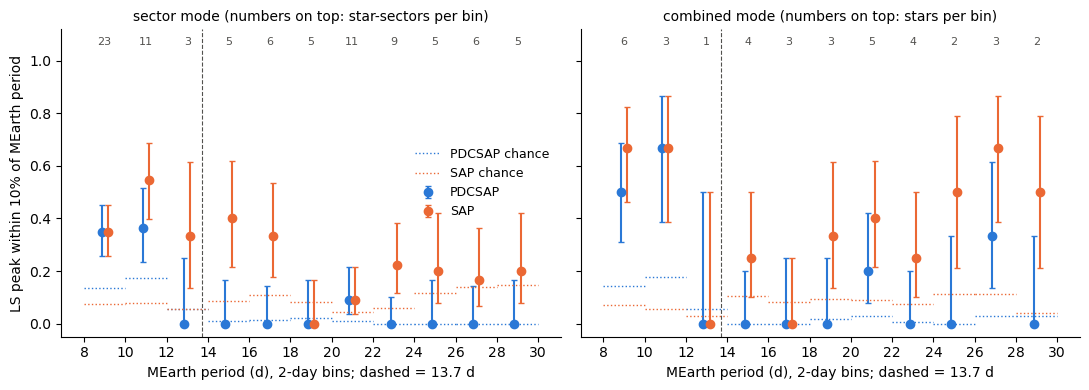

In [2]:
rates = pd.concat([granular_mearth.binned_rates(pd.read_csv(results / f"ls_{flux}.csv", dtype={"sector": str}), flux) for flux in ["pdcsap", "sap"]])
fig = granular_mearth.plot(rates)

```
12-30 d: 1-6 stars per bin  -->  error bars span ~0-50%  -->  cannot locate the drop to within a few days
```
What it does show: the same star-sectors give different answers in PDCSAP and SAP.

In [3]:
paired = pd.read_csv(results / "step3_sap_vs_pdcsap.csv", dtype={"sector": str})
paired = paired[(paired["truth"] == "MEarth") & (paired["mode"] == "sector") & paired["period"].between(12, 20)]
paired["P bin (d)"] = pd.cut(paired["period"], [12, 14, 16, 18, 20], right=False).astype(str)
table = paired.groupby("P bin (d)").agg(
    star_sectors=("tic_id", "size"),
    PDCSAP_hits=("outcome_pdcsap", lambda s: int((s == "hit").sum())),
    SAP_hits=("outcome_sap", lambda s: int((s == "hit").sum())),
)
table.loc["12-20 d total"] = table.sum()
table

,star_sectors,PDCSAP_hits,SAP_hits
P bin (d),,,
"[12, 14)",3,0,1
"[14, 16)",5,0,2
"[16, 18)",6,0,2
"[18, 20)",5,0,0
12-20 d total,19,0,5


## 2. Emily Pass's samples
```
Pass+2023 (AJ 166, 16)   : 123 active M dwarfs within 15 pc, AAS machine-readable Table 1
Pass+2022 (ApJ 936, 109) : M dwarfs in wide binaries, periods parsed from the arXiv LaTeX source (no machine-readable table)
usable truth star = period in 12-20 d  AND  not already in our MEarth table  AND  not measured with TESS (else circular)
```

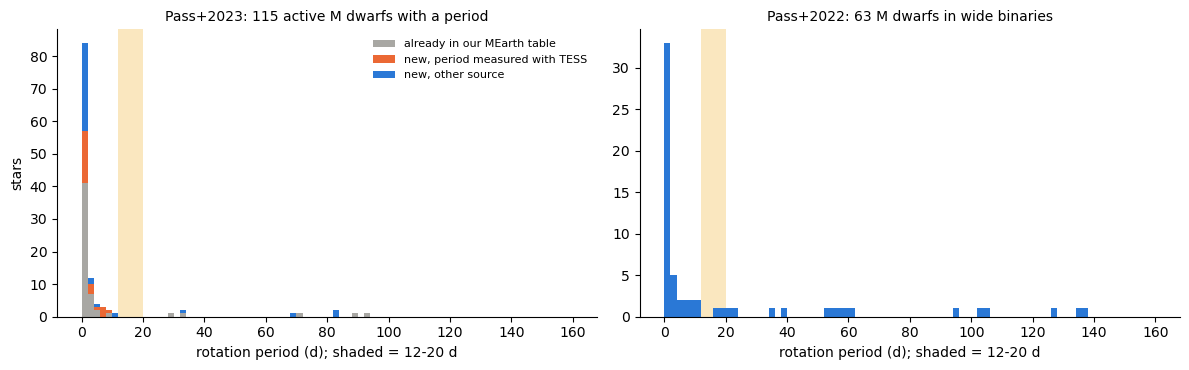

In [4]:
pass2023 = pass_samples.load_pass2023()
pass2022 = pass_samples.load_pass2022()
fig = pass_samples.plot_periods(pass2023, pass2022)

Same histograms on a log period axis (spreads out the < 2 d pile-up):

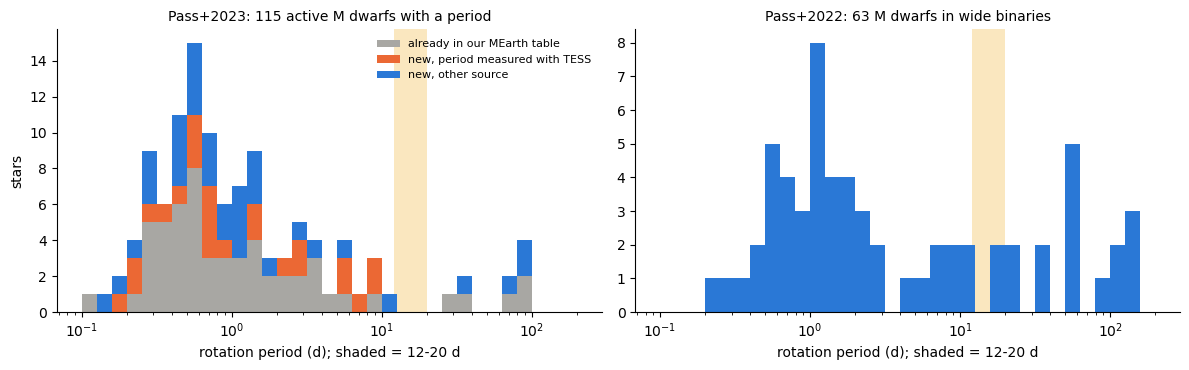

In [5]:
fig = pass_samples.plot_periods(pass2023, pass2022, log_x=True)

### 2a. Pass+2023 counts per period bin

In [6]:
labels = ["< 2", "2-10", "10-12", "12-20", "20-27", "> 27"]
pass2023["P bin (d)"] = pd.cut(pass2023["period"], [0, 2, 10, 12, 20, 27, 1000], right=False, labels=labels)
counts = pd.crosstab(pass2023["P bin (d)"], pass2023["group"], dropna=False).reindex(labels, fill_value=0)
counts["total"] = counts.sum(axis=1)
counts.style.apply(lambda row: ["background-color: #fbe6c2" if row.name in ["12-20", "20-27"] else "" for _ in row], axis=1)

group,already in our MEarth table,"new, other source","new, period measured with TESS",total
P bin (d),,,,
< 2,41,27,16,84
2-10,10,3,8,21
10-12,0,1,0,1
12-20,0,0,0,0
20-27,0,0,0,0
> 27,5,4,0,9


### 2b. How the three groups are assigned
```
Pass+2023 star --> 2MASS ID in our MEarth table?   yes --> "already in our MEarth table"
                        | no
                        v
                   Ref code = 8 or 10?              yes --> "new, period measured with TESS"
                        | no
                        v
                   "new, other source"
```
Raw `Ref` column of Pass+2023 Table 1 (one code per star; blank = no period):

In [7]:
display(pass2023[["Name", "period", "Ref"]].head(8))
pass2023["Ref"].fillna("(blank)").value_counts().rename_axis("Ref").to_frame("stars").T

,Name,period,Ref
0,2MA0505-4756,0.726,3
1,2MA2009-0113,1.374,2
2,APCOL,1.013,3
3,APM0237-5928,0.469,2
4,G141-36,2.756,1
5,G169-29,0.898,4
6,G180-60,0.512,8
7,G192-12B,0.951,1


Ref,1,3,2,8,10,(blank),4,9,7,5,6
stars,38,17,17,13,11,8,7,7,2,2,1


What each code means (MRT Note 3) and what Pass+2023 says about it:

In [8]:
refs = pd.DataFrame([
    (1, "Newton+2016", "MEarth"),
    (2, "Newton+2018", "MEarth"),
    (3, "Medina+2020", "TESS primary mission stars; 'did not measure any TESS rotation periods longer than 6' d"),
    (4, "Medina+2022b", "TESS primary mission stars"),
    (5, "Pass+2022", "TESS SAP/PDCSAP or MEarth, per star"),
    (6, "Kiraga 2012", "literature; 'insufficient data for a TESS or MEarth detection'"),
    (7, "Diez Alonso+2019", "literature; 'insufficient data for a TESS or MEarth detection'"),
    (8, "Pass+2023", "TESS"),
    (9, "Pass+2023", "MEarth"),
    (10, "Pass+2023", "TESS + MEarth"),
], columns=["Ref", "paper", "data (Pass+2023 wording)"])
refs["Ref"] = refs["Ref"].astype(str)
per_group = pd.crosstab(pass2023["Ref"].astype(str), pass2023["group"]).reset_index()
refs.merge(per_group, on="Ref", how="left").fillna(0).set_index("Ref")

,paper,data (Pass+2023 wording),already in our MEarth table,"new, other source","new, period measured with TESS"
Ref,,,,,
1,Newton+2016,MEarth,38,0,0
2,Newton+2018,MEarth,17,0,0
3,Medina+2020,TESS primary mission stars; 'did not measure any TESS rotation periods longer than 6' d,1,16,0
4,Medina+2022b,TESS primary mission stars,0,7,0
5,Pass+2022,"TESS SAP/PDCSAP or MEarth, per star",0,2,0
6,Kiraga 2012,literature; 'insufficient data for a TESS or MEarth detection',0,1,0
7,Diez Alonso+2019,literature; 'insufficient data for a TESS or MEarth detection',0,2,0
8,Pass+2023,TESS,0,0,13
9,Pass+2023,MEarth,0,7,0


```
"new, other source" = Ref 3, 4, 5, 6, 7, 9 (35 stars) + blank Ref (8 stars, no period) = 43
                    -->  not purely non-TESS: Medina (3, 4) and Pass+2022 (5) include TESS periods
does not change section 2a: every group has 0 stars at 12-27 d
```

## 3. McQuillan+2013 Kepler M dwarfs
```
McQuillan, Aigrain & Mazeh 2013 (MNRAS 432, 1203): 1570 Kepler M dwarfs with a rotation period (table: arXiv 1303.6787, anc/)
  --> (1) KIC -> TIC (MAST TIC v8.2, KIC column; 43 without a clean match)
  --> (2) SPOC 2-min sectors, same filter as the MEarth table
  --> (3) same LS, same hit rule, 8-30 d only
```
Stars and star-sectors per bin, next to MEarth:

In [9]:
mcq_counts = pd.read_csv(results / "mcquillan_spoc_summary.csv")
mearth_counts = pd.read_csv(results / "granular_mearth.csv").query("flux == 'pdcsap' and mode == 'sector'")
counts = mcq_counts.merge(mearth_counts[["bin_low", "n_stars", "n"]].rename(columns={"n_stars": "MEarth stars", "n": "MEarth star-sectors"}), on="bin_low")
counts.rename(columns={"n_with_spoc_2min": "McQuillan stars", "n_star_sectors": "McQuillan star-sectors"})[
    ["bin_low", "bin_high", "McQuillan stars", "McQuillan star-sectors", "MEarth stars", "MEarth star-sectors"]]

,bin_low,bin_high,McQuillan stars,McQuillan star-sectors,MEarth stars,MEarth star-sectors
0,8,10,9,19,6,23
1,10,12,17,46,3,11
2,12,14,23,54,1,3
3,14,16,53,153,4,5
4,16,18,73,187,3,6
5,18,20,98,244,3,5
6,20,22,67,155,5,11
7,22,24,39,84,4,9
8,24,26,36,95,2,5
9,26,28,38,95,3,6


Same plot as section 1, McQuillan stars. Dotted = chance (defined in section 1).
```
hit rate well above chance  -->  LS recovers the period in that bin
hit rate ~ chance           -->  it does not
```

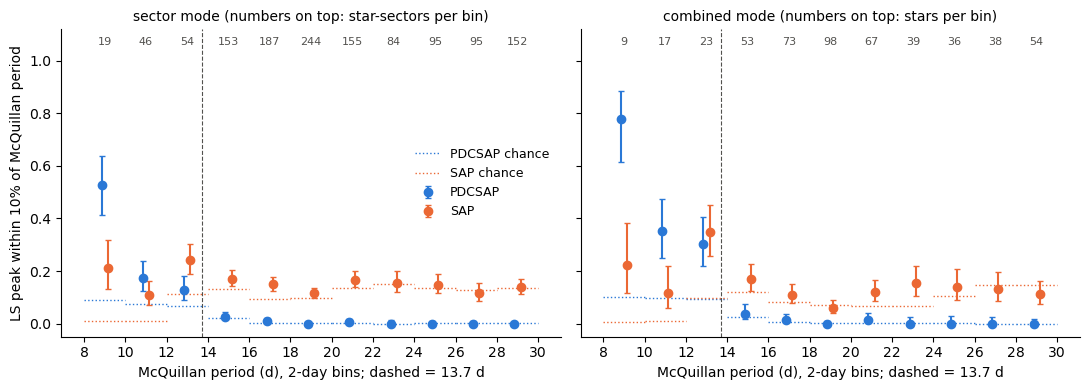

In [10]:
mcq_rates = pd.concat([granular_mearth.binned_rates(pd.read_csv(results / f"ls_{flux}_mcquillan.csv", dtype={"sector": str}), flux, "mcquillan") for flux in ["pdcsap", "sap"]])
fig = granular_mearth.plot(mcq_rates, "McQuillan")

Combined mode (one periodogram per star), hit rate vs chance:

In [11]:
combined = mcq_rates[mcq_rates["mode"] == "combined"]
combined.pivot(index=["bin_low", "n"], columns="flux", values=["hit_rate", "chance_rate"]).round(3)

hit_rate        chance_rate       
flux         pdcsap    sap      pdcsap    sap
bin_low n                                    
8       9     0.778  0.222       0.102  0.006
10      17    0.353  0.118       0.098  0.010
12      23    0.304  0.348       0.095  0.097
14      53    0.038  0.170       0.025  0.118
16      73    0.014  0.110       0.005  0.083
18      98    0.000  0.061       0.002  0.071
20      67    0.015  0.119       0.001  0.065
22      39    0.000  0.154       0.002  0.067
24      36    0.000  0.139       0.002  0.105
26      38    0.000  0.132       0.000  0.147
28      54    0.000  0.111       0.000  0.147

SAP at 14-30 d, all bins pooled (combined mode):

In [12]:
sap_long = combined[(combined["flux"] == "sap") & (combined["bin_low"] >= 14)]
n, hits = sap_long["n"].sum(), sap_long["hits"].sum()
expected = (sap_long["chance_rate"] * sap_long["n"]).sum()
sigma = (expected * (1 - expected / n)) ** 0.5
pd.DataFrame([{"stars": n, "hits": hits, "expected by chance": round(expected, 1), "excess / sigma": round((hits - expected) / sigma, 1)}])

,stars,hits,expected by chance,excess / sigma
0,458,53,43.6,1.5


```
PDCSAP: 30-78% at 8-14 d  -->  <= 4% from 14 d on, close to chance (0 of 98 stars at 18-20 d)
SAP   : 14-30 d close to chance; pooled excess ~1.5 sigma  -->  no clear long-period recovery either
SAP   : 8-12 d far below PDCSAP  -->  SAP peaks are dominated by long-period systematics
```
Not explained by brightness alone: these stars are fainter (median Tmag 14.3 vs 11.8 for the MEarth stars at 8-30 d),
but within McQuillan the SAP hit rate at 14-30 d does not change with Tmag (12.8% for Tmag < 13.5, n = 78; 11.0% for Tmag > 14.3, n = 245).
MEarth SAP sits above chance at 14-30 d, but with 2-5 stars per bin; the two samples disagree and this notebook does not say why.